# ⚽ EDA v2 — Notre propre Elo : global, Ligue des Champions et championnat

**Auteur :** Moussa — branche `feature/elo`

## Pourquoi ce notebook ?

Le professeur nous a demandé de **séparer l'Elo de la Ligue des Champions et l'Elo du championnat**. L'Elo officiel (`EloRatings.csv`) mélange tous les matchs. Il a aussi un autre défaut, repéré dans l'EDA : il ne couvre que 19 pays, donc **22 clubs sur 106** n'ont pas d'Elo.

**Notre solution :** calculer **nous-mêmes** l'Elo à partir de `games.csv`, qui contient tous les matchs (championnats, coupes, C1, Ligue Europa, qualifications…). On en tire 3 versions :

| Elo | Calculé avec | Question à laquelle il répond |
|---|---|---|
| **Elo global** | tous les matchs de clubs | quel est le niveau général du club ? |
| **Elo C1** | seulement les matchs de Ligue des Champions | quel est son niveau **en C1** ? |
| **Elo championnat** | seulement les matchs de championnat | quel est son niveau **dans son championnat** ? |

## Plan
1. La formule de l'Elo
2. Calcul des 3 Elo
3. Vérification : notre Elo est-il fiable ?
4. Quel Elo prédit le mieux les matchs de C1 ?
5. Le cas du PSG : C1 contre championnat
6. Les 36 participants de 2026-2027
7. Sauvegarde et conclusion

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%config InlineBackend.figure_format = 'retina'
BLEU, ORANGE, VERT, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#b5b3ad'

games = pd.read_csv('../data/games.csv')
events = pd.read_csv('../data/game_events.csv', usecols=['game_id', 'type'])
elo_officiel = pd.read_csv('../data/EloRatings.csv')

# On garde les matchs de clubs (pas les équipes nationales), dans l'ordre chronologique
matchs = games[games['competition_type'] != 'national_team_competition'].copy()
matchs['date'] = pd.to_datetime(matchs['date'])
matchs = matchs.sort_values(['date', 'game_id']).reset_index(drop=True)

# Comme dans l'EDA : un match décidé aux tirs au but est un match nul
matchs['tirs_au_but'] = matchs['game_id'].isin(events.loc[events['type'] == 'Shootout', 'game_id'])

# Score du point de vue de l'équipe à domicile : 1 = victoire, 0,5 = nul, 0 = défaite
matchs['score'] = np.select(
    [matchs['tirs_au_but'] | (matchs['home_club_goals'] == matchs['away_club_goals']),
     matchs['home_club_goals'] > matchs['away_club_goals']],
    [0.5, 1.0],
    default=0.0,
)

# Terrain neutre : les finales, et le tournoi final de Lisbonne en 2020 (saison 2019)
r = matchs['round'].str.lower()
matchs['neutre'] = (r == 'final') | ((matchs['competition_id'] == 'CL') & (matchs['season'] == 2019)
                                      & r.isin(['quarter-finals', 'semi-finals']))

print(f"Matchs de clubs : {len(matchs):,} (du {matchs['date'].min().date()} au {matchs['date'].max().date()})")
print(f"Dont Ligue des Champions : {(matchs['competition_id'] == 'CL').sum():,}")
print(f"Dont championnats : {(matchs['competition_type'] == 'domestic_league').sum():,}")

Matchs de clubs : 88,216 (du 2012-07-03 au 2026-07-06)
Dont Ligue des Champions : 1,871
Dont championnats : 63,382


# 1. La formule de l'Elo

L'Elo est une **note de niveau** qui se met à jour après chaque match. Le principe tient en 3 étapes.

**① Avant le match, on calcule le résultat attendu.** Il dépend de l'écart d'Elo entre les deux équipes :

$$\text{attendu} = \frac{1}{1 + 10^{-(\text{Elo}_{dom} + H - \text{Elo}_{ext}) / 400}}$$

C'est un nombre entre 0 et 1 : 0,5 veut dire « match équilibré », 0,8 veut dire « l'équipe à domicile est nettement favorite ». **H = 60 points** est le bonus de l'équipe à domicile (0 sur terrain neutre).

**② Après le match, on compare au résultat réel** : 1 pour une victoire, 0,5 pour un nul, 0 pour une défaite.

**③ On met l'Elo à jour :**

$$\text{nouvel Elo} = \text{Elo} + K \times (\text{réel} - \text{attendu})$$

**K = 20** fixe la vitesse à laquelle l'Elo bouge. Les points gagnés par l'un sont perdus par l'autre.

**L'idée clé :** on gagne beaucoup de points quand on **crée la surprise**, et très peu quand on gagne un match attendu. Tous les clubs commencent à **1 500 points**.

**Exemple (cellule suivante) :** une équipe à 1 800 qui reçoit une équipe à 1 600 a un résultat attendu de 0,82. Si elle gagne, elle ne prend que 4 points. Si elle perd, elle en perd 16.

In [11]:
K, H, DEPART = 20, 60, 1500   # vitesse, bonus domicile, Elo de départ

def resultat_attendu(elo_dom, elo_ext, neutre=False):
    # Probabilité « attendue » de victoire de l'équipe à domicile (un nul compte pour moitié)
    bonus = 0 if neutre else H
    return 1 / (1 + 10 ** (-(elo_dom + bonus - elo_ext) / 400))

# Exemple : une équipe à 1 800 reçoit une équipe à 1 600
attendu = resultat_attendu(1800, 1600)
print(f"Résultat attendu pour l'équipe à domicile : {attendu:.2f}")
print(f"Si elle gagne : {K * (1 - attendu):+.1f} points")
print(f"Match nul     : {K * (0.5 - attendu):+.1f} points")
print(f"Si elle perd  : {K * (0 - attendu):+.1f} points")

Résultat attendu pour l'équipe à domicile : 0.82
Si elle gagne : +3.7 points
Match nul     : -6.3 points
Si elle perd  : -16.3 points


# 2. Calcul des 3 Elo

La fonction `calculer_elo` parcourt les matchs **dans l'ordre des dates**. Pour chaque match, elle :
1. **note l'Elo des deux clubs AVANT le match** : c'est la valeur qu'on utilisera pour prédire, sans fuite d'information ;
2. met à jour l'Elo des deux clubs avec la formule.

On l'applique 3 fois, sur 3 ensembles de matchs :
- **global** : tous les matchs de clubs ;
- **C1** : seulement la Ligue des Champions ;
- **championnat** : seulement les championnats.

Pour l'Elo championnat, un match de C1 n'est pas un match de championnat. On va donc chercher, comme dans l'EDA avec `merge_asof`, le **dernier Elo championnat du club avant la date du match de C1**.

**Résultat :**
- l'Elo global couvre **100 %** des matchs de C1, contre 80 % pour l'Elo officiel ;
- l'Elo C1 en couvre 96 % : il n'est pas défini pour le tout premier match de C1 d'un club ;
- l'Elo championnat en couvre 84 % : 13 clubs (Chypre, Israël, Bulgarie, Azerbaïdjan…) n'ont pas leur championnat dans `games.csv`.

In [12]:
def calculer_elo(m):
    # Calcule l'Elo match après match. Renvoie l'Elo AVANT chaque match et l'historique des Elo.
    elo = {}                          # Elo actuel de chaque club : {club_id: elo}
    avant_dom, avant_ext, historique = [], [], []
    for date, dom, ext, score, neutre in zip(m['date'], m['home_club_id'], m['away_club_id'],
                                             m['score'], m['neutre']):
        elo_dom, elo_ext = elo.get(dom, DEPART), elo.get(ext, DEPART)
        avant_dom.append(elo_dom)     # 1) on note l'Elo AVANT le match
        avant_ext.append(elo_ext)
        variation = K * (score - resultat_attendu(elo_dom, elo_ext, neutre))
        elo[dom] = elo_dom + variation    # 2) on met à jour : ce que l'un gagne, l'autre le perd
        elo[ext] = elo_ext - variation
        historique += [(date, dom, elo[dom]), (date, ext, elo[ext])]
    return np.array(avant_dom), np.array(avant_ext), pd.DataFrame(historique, columns=['date', 'club_id', 'elo'])

est_c1 = matchs['competition_id'] == 'CL'
est_championnat = matchs['competition_type'] == 'domestic_league'

dom_global, ext_global, histo_global = calculer_elo(matchs)
dom_c1, ext_c1, histo_c1 = calculer_elo(matchs[est_c1])
_, _, histo_champ = calculer_elo(matchs[est_championnat])

# Table finale : un match de C1 par ligne, avec les 3 Elo des deux clubs avant le match
c1 = matchs[est_c1].copy()
c1['home_elo_global'], c1['away_elo_global'] = dom_global[est_c1.to_numpy()], ext_global[est_c1.to_numpy()]
c1['home_elo_c1'], c1['away_elo_c1'] = dom_c1, ext_c1

# Elo C1 indéfini pour le tout premier match de C1 d'un club (il n'a encore jamais joué la C1)
deja_vus = set()
for i, (d, e) in zip(c1.index, zip(c1['home_club_id'], c1['away_club_id'])):
    if d not in deja_vus: c1.loc[i, 'home_elo_c1'] = np.nan
    if e not in deja_vus: c1.loc[i, 'away_elo_c1'] = np.nan
    deja_vus |= {d, e}

# Elo championnat : le dernier connu AVANT le match de C1 (comme dans l'EDA)
histo_champ = histo_champ.sort_values('date')
for cote in ['home', 'away']:
    c1 = pd.merge_asof(
        c1.sort_values('date'),
        histo_champ.rename(columns={'club_id': f'{cote}_club_id', 'elo': f'{cote}_elo_champ'}),
        on='date', by=f'{cote}_club_id', allow_exact_matches=False)

for nom in ['global', 'c1', 'champ']:
    couverture = c1[[f'home_elo_{nom}', f'away_elo_{nom}']].notna().all(axis=1).mean()
    print(f"Elo {nom:6} : connu pour les deux clubs dans {couverture:.0%} des matchs de C1")

Elo global : connu pour les deux clubs dans 100% des matchs de C1
Elo c1     : connu pour les deux clubs dans 96% des matchs de C1
Elo champ  : connu pour les deux clubs dans 84% des matchs de C1


# 3. Vérification : notre Elo est-il fiable ?

**Question :** avant d'utiliser notre Elo, il faut vérifier qu'il mesure bien le niveau des clubs. On le compare à l'**Elo officiel**, sur les 1 500 matchs de C1 où les deux existent. On reprend la table de correspondance des noms de l'EDA.

**Résultat :**
- les **écarts d'Elo** entre deux équipes sont fortement corrélés entre les deux sources (**0,78**). Les deux Elo racontent la même histoire ;
- sur ces 1 500 matchs, la règle « le meilleur Elo gagne » a raison dans **54,6 %** des cas avec notre Elo, contre **56,2 %** avec l'Elo officiel ;
- mais notre Elo couvre aussi les **371 matchs** sans Elo officiel, et il y a raison dans **61,7 %** des cas.

**Interprétation :** notre Elo est **un peu moins précis** que l'officiel, mais il est **complet**.

**Pourquoi un peu moins précis ?** L'Elo officiel est calculé depuis des dizaines d'années, alors que le nôtre part de 1 500 pour tous les clubs avec des données qui commencent vers 2012. Il lui faut quelques saisons pour « apprendre » le niveau de chaque club.

In [13]:
# Table de correspondance des noms (reprise de l'EDA) : nom dans games -> nom dans elo_officiel
correspondance = {
    'Arsenal FC': 'Arsenal', 'Aston Villa': 'Aston Villa', 'Chelsea FC': 'Chelsea', 'Leicester City': 'Leicester',
    'Liverpool FC': 'Liverpool', 'Manchester City': 'Man City', 'Manchester United': 'Man United',
    'Newcastle United': 'Newcastle', 'Tottenham Hotspur': 'Tottenham',
    'Athletic Bilbao': 'Ath Bilbao', 'Atlético de Madrid': 'Ath Madrid', 'FC Barcelona': 'Barcelona',
    'Girona FC': 'Girona', 'Málaga CF': 'Malaga', 'Real Madrid': 'Real Madrid', 'Real Sociedad': 'Sociedad',
    'Sevilla FC': 'Sevilla', 'Valencia CF': 'Valencia', 'Villarreal CF': 'Villarreal',
    '1.FC Union Berlin': 'Union Berlin', 'Bayer 04 Leverkusen': 'Leverkusen', 'Bayern Munich': 'Bayern Munich',
    'Borussia Dortmund': 'Dortmund', 'Borussia Mönchengladbach': 'MGladbach', 'Eintracht Frankfurt': 'Ein Frankfurt',
    'FC Schalke 04': 'Schalke 04', 'RB Leipzig': 'RB Leipzig', 'TSG 1899 Hoffenheim': 'Hoffenheim',
    'VfB Stuttgart': 'Stuttgart', 'VfL Wolfsburg': 'Wolfsburg',
    'AC Milan': 'Milan', 'Associazione Sportiva Roma': 'Roma', 'Atalanta BC': 'Atalanta',
    'Bologna Football Club 1909': 'Bologna', 'Inter Milan': 'Inter', 'Juventus FC': 'Juventus',
    'SSC Napoli': 'Napoli', 'Società Sportiva Lazio S.p.A.': 'Lazio',
    'AS Monaco': 'Monaco', 'LOSC Lille': 'Lille', 'Montpellier HSC': 'Montpellier', 'Olympique Lyon': 'Lyon',
    'Olympique Marseille': 'Marseille', 'Paris Saint-Germain': 'Paris SG', 'RC Lens': 'Lens',
    'Stade Brestois 29': 'Brest', 'Stade Rennais FC': 'Rennes',
    'Ajax Amsterdam': 'Ajax', 'Feyenoord Rotterdam': 'Feyenoord', 'PSV Eindhoven': 'PSV Eindhoven',
    'FC Porto': 'Porto', 'SC Braga': 'Sp Braga', 'SL Benfica': 'Benfica', 'Sporting CP': 'Sp Lisbon',
    'Club Brugge KV': 'Club Brugge', 'KAA Gent': 'Gent', 'KRC Genk': 'Genk', 'RSC Anderlecht': 'Anderlecht',
    'Royal Antwerp FC': 'Antwerp', 'Union Saint-Gilloise': 'St. Gilloise',
    'Austria Vienna': 'Austria Wien', 'Fußballclub Red Bull Salzburg': 'Salzburg',
    'Sportklub Puntigamer Sturm Graz': 'Sturm Graz', 'Celtic FC': 'Celtic', 'Rangers FC': 'Rangers',
    'FC Copenhagen': 'FC Kobenhavn', 'FC Midtjylland': 'Midtjylland', 'FC Nordsjaelland': 'Nordsjaelland',
    'Athlitiki Enosi Konstantinoupoleos': 'AEK', 'Olympiakos Syndesmos Filathlon Peiraios': 'Olympiakos',
    'Basaksehir FK': 'Buyuksehyr', 'Beşiktaş Jimnastik Kulübü': 'Besiktas', 'Galatasaray': 'Galatasaray',
    'AO FK Zenit Sankt-Peterburg': 'Zenit', 'FK Krasnodar': 'FC Krasnodar', 'FK Rostov': 'Rostov',
    'FK Spartak Moskva': 'Spartak Moskva', 'PFK CSKA Moskva': 'CSKA Moskva',
    'Футбольный клуб "Локомотив" Москва': 'Lok Moskva',
    'CFR Cluj': 'CFR Cluj', 'FCSB': 'Steaua', 'Legia Warszawa': 'Legia',
    'Fotballklubben Bodø/Glimt': 'Bodoe Glimt', 'Malmö Fotbollförening': 'Malmoe',
}

# Elo officiel juste avant chaque match (même méthode que dans l'EDA)
elo_officiel['date'] = pd.to_datetime(elo_officiel['date'])
officiel = elo_officiel.sort_values('date')[['date', 'club', 'elo']]
verif = c1.sort_values('date').copy()
for cote in ['home', 'away']:
    verif[f'{cote}_nom_officiel'] = verif[f'{cote}_club_name'].map(correspondance)
    verif = pd.merge_asof(verif, officiel.rename(columns={'club': f'{cote}_nom_officiel', 'elo': f'{cote}_elo_officiel'}),
                          on='date', by=f'{cote}_nom_officiel', allow_exact_matches=False)

# Résultat réel vu de l'équipe à domicile : 1 victoire, 0 nul, -1 défaite
verif['resultat'] = np.sign(verif['score'] - 0.5)

def taux_reussite(df, nom):
    # % de matchs où l'équipe au meilleur Elo a gagné (on ignore les rares égalités parfaites d'Elo)
    ecart = df[f'home_elo_{nom}'] - df[f'away_elo_{nom}']
    ok = ecart.notna() & (ecart != 0)
    return (np.sign(ecart[ok]) == df.loc[ok, 'resultat']).mean()

commun = verif.dropna(subset=['home_elo_officiel', 'away_elo_officiel'])
sans_officiel = verif[verif['home_elo_officiel'].isna() | verif['away_elo_officiel'].isna()]
correlation = np.corrcoef(commun['home_elo_global'] - commun['away_elo_global'],
                          commun['home_elo_officiel'] - commun['away_elo_officiel'])[0, 1]

print(f"Matchs où l'on a les deux Elo : {len(commun)}")
print(f"Corrélation des écarts d'Elo (notre global / officiel) : {correlation:.2f}")
print(f"« Meilleur Elo gagne » avec l'Elo officiel : {taux_reussite(commun, 'officiel'):.1%}")
print(f"« Meilleur Elo gagne » avec notre Elo global : {taux_reussite(commun, 'global'):.1%}")
print(f"Matchs SANS Elo officiel : {len(sans_officiel)} → notre Elo global y a raison dans {taux_reussite(sans_officiel, 'global'):.1%}")

Matchs où l'on a les deux Elo : 1500
Corrélation des écarts d'Elo (notre global / officiel) : 0.78
« Meilleur Elo gagne » avec l'Elo officiel : 56.2%
« Meilleur Elo gagne » avec notre Elo global : 54.6%
Matchs SANS Elo officiel : 371 → notre Elo global y a raison dans 61.7%


## 3.1 Le choix des réglages K et H

**Question :** nos réglages (K = 20, H = 60) sont-ils bien choisis ? On recalcule l'Elo global avec d'autres valeurs, et on mesure à chaque fois le % de matchs de C1 bien prédits.

**Résultat :** tous les réglages donnent **entre 55 % et 56 %**, et K = 20, H = 60 fait partie des meilleurs. Notre conclusion **ne dépend donc pas** d'un réglage précis : c'est un signe de solidité.

Nous avons aussi testé une variante où l'**écart de buts** compte (une victoire 4-0 rapporte plus qu'une victoire 1-0). Elle ne faisait pas mieux (55,5 %) : nous avons gardé la version la plus simple.

In [14]:
# Sensibilité : on recalcule l'Elo global pour plusieurs K et H, et on mesure la réussite en C1
resultats = {}
for k_test in [10, 20, 30, 40]:
    for h_test in [0, 60, 100]:
        K, H = k_test, h_test
        dom, ext, _ = calculer_elo(matchs)
        ecart = (dom - ext)[est_c1.to_numpy()]
        reel = np.sign(matchs.loc[est_c1, 'score'] - 0.5).to_numpy()
        resultats[(k_test, h_test)] = (np.sign(ecart) == reel).mean() * 100
K, H = 20, 60   # on remet les réglages choisis

pd.Series(resultats).unstack().round(1).rename_axis(index='K', columns='H (bonus domicile)')

H (bonus domicile),0,60,100
K,,,
10,55.4,55.4,55.2
20,55.9,56.0,55.7
30,55.7,55.3,55.5
40,54.9,55.2,55.3


# 4. Quel Elo prédit le mieux les matchs de C1 ?

**Question (celle du professeur) :** faut-il un Elo **spécial C1**, ou le niveau en championnat suffit-il ?

On compare la règle « le meilleur Elo gagne » avec nos 3 Elo, sur les matchs de C1 où ils sont connus.

**Résultat :**
- **Elo global : 56 %** et **Elo C1 : 56 %**, au même niveau que l'Elo officiel ;
- **Elo championnat : 48 %**, soit **pas mieux que la règle « l'équipe à domicile gagne »**.

**Interprétation :** l'Elo championnat n'est **pas comparable d'un pays à l'autre**. Il mesure le niveau d'un club **par rapport à son propre championnat** : un club à 1 800 en Norvège n'a pas le même niveau qu'un club à 1 800 en Allemagne. Or en C1, on oppose presque toujours des clubs de pays différents. Les Elo global et C1, eux, contiennent des matchs **entre pays** (les coupes d'Europe), ce qui permet de comparer les championnats.

**⚠️ Limite :** l'Elo C1 repose sur peu de matchs par club (6 à 13 par saison). Il réagit donc moins vite que l'Elo global.

                 Elo  reussite
            Officiel      56.2
     Global (maison)      56.0
         C1 (maison)      55.8
Championnat (maison)      48.2


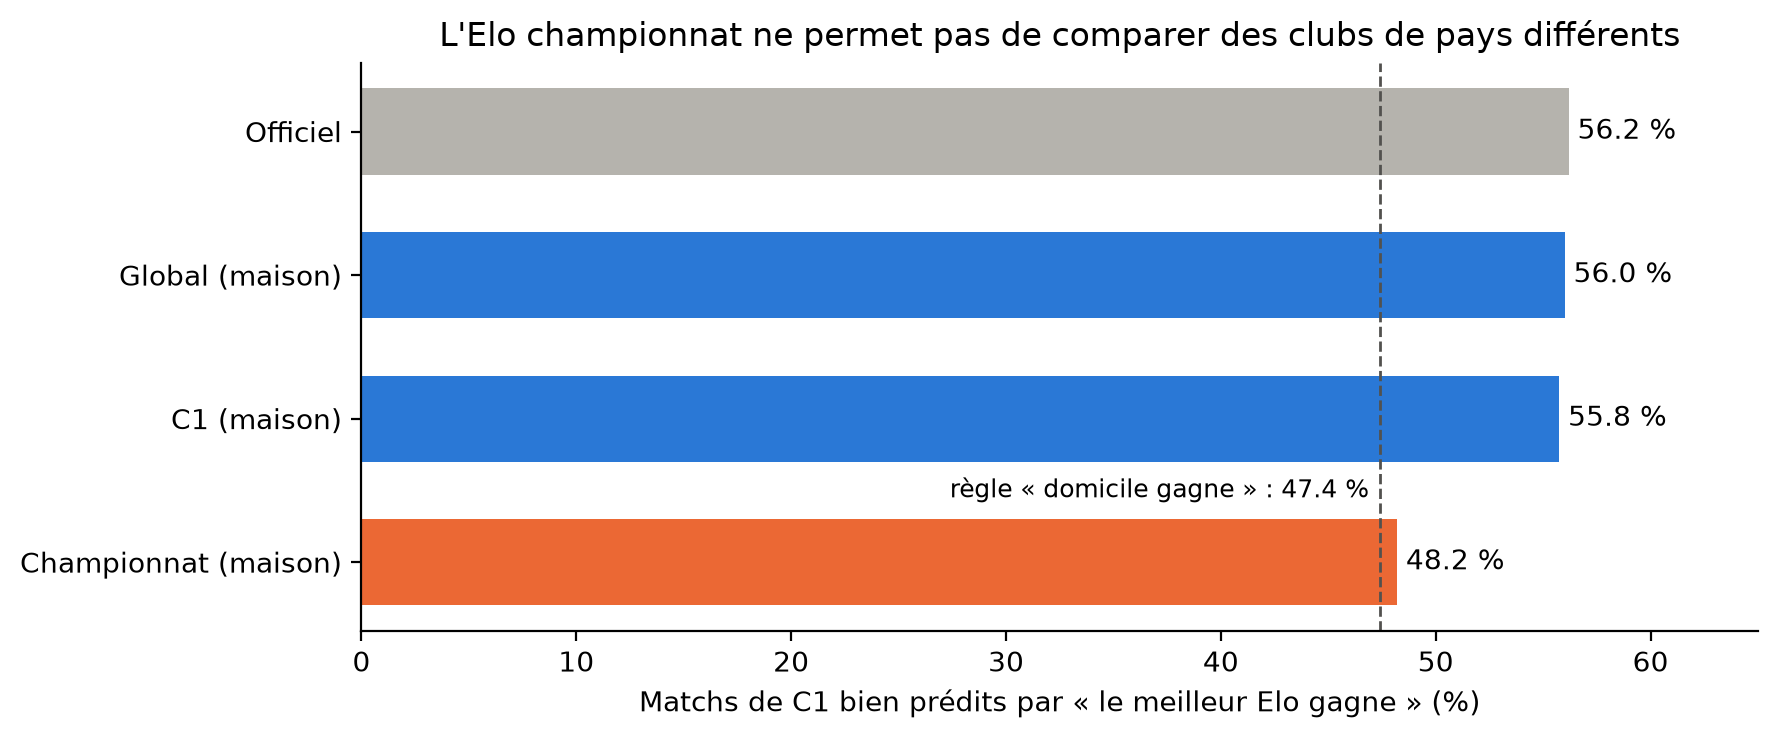

In [15]:
comparaison = pd.DataFrame({
    'Elo': ['Officiel', 'Global (maison)', 'C1 (maison)', 'Championnat (maison)'],
    'reussite': [taux_reussite(commun, 'officiel'), taux_reussite(verif, 'global'),
                 taux_reussite(verif, 'c1'), taux_reussite(verif, 'champ')],
})
comparaison['reussite'] *= 100
print(comparaison.round(1).to_string(index=False))

regle_domicile = (verif['resultat'] == 1).mean() * 100
couleurs = [GRIS, BLEU, BLEU, ORANGE]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(comparaison['Elo'], comparaison['reussite'], color=couleurs, height=0.6)
for y, v in enumerate(comparaison['reussite']):
    ax.text(v + 0.4, y, f"{v:.1f} %", va='center')
ax.axvline(regle_domicile, color='#52514e', linestyle='--', linewidth=1)
ax.text(regle_domicile - 0.5, 2.5, f"règle « domicile gagne » : {regle_domicile:.1f} %", fontsize=9, ha='right', va='center')
ax.invert_yaxis()
ax.set_xlim(0, 65)
ax.set_xlabel('Matchs de C1 bien prédits par « le meilleur Elo gagne » (%)')
ax.set_title("L'Elo championnat ne permet pas de comparer des clubs de pays différents")
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# 5. Le cas du PSG : Elo C1 contre Elo championnat

**Hypothèse (issue de l'EDA) :** l'Elo officiel du PSG baisse au printemps 2026, alors qu'il élimine Liverpool et le Bayern en C1. L'Elo officiel mélange tout : le PSG perdrait-il des points **en championnat**, tout en restant fort **en C1** ?

**Test :** on suit l'Elo C1 et l'Elo championnat du PSG pendant la saison 2025-2026. Les deux Elo n'ont pas la même échelle, donc on regarde leur **variation depuis le début de la saison** (août 2025).

**Résultat :** sur la saison, l'Elo **C1** du PSG **gagne 51 points**, surtout au printemps (élimination de Liverpool et du Bayern). Au même moment, son Elo **championnat** **baisse** et finit à **−25 points**.

**Interprétation :** les données confirment que le PSG est **plus performant en C1 qu'en Ligue 1** sur cette saison. Un Elo qui mélange les deux le **sous-estime** pour la C1.

**⚠️ Limite :** on ne sait toujours pas **pourquoi** (rotation de l'effectif, motivation, calendrier). Le notebook « joueurs » pourra vérifier l'hypothèse de la rotation.

Elo C1 : 1661 avant la saison → 1712 à la fin (+51)
Elo championnat (Ligue 1) : 1814 avant la saison → 1789 à la fin (-25)


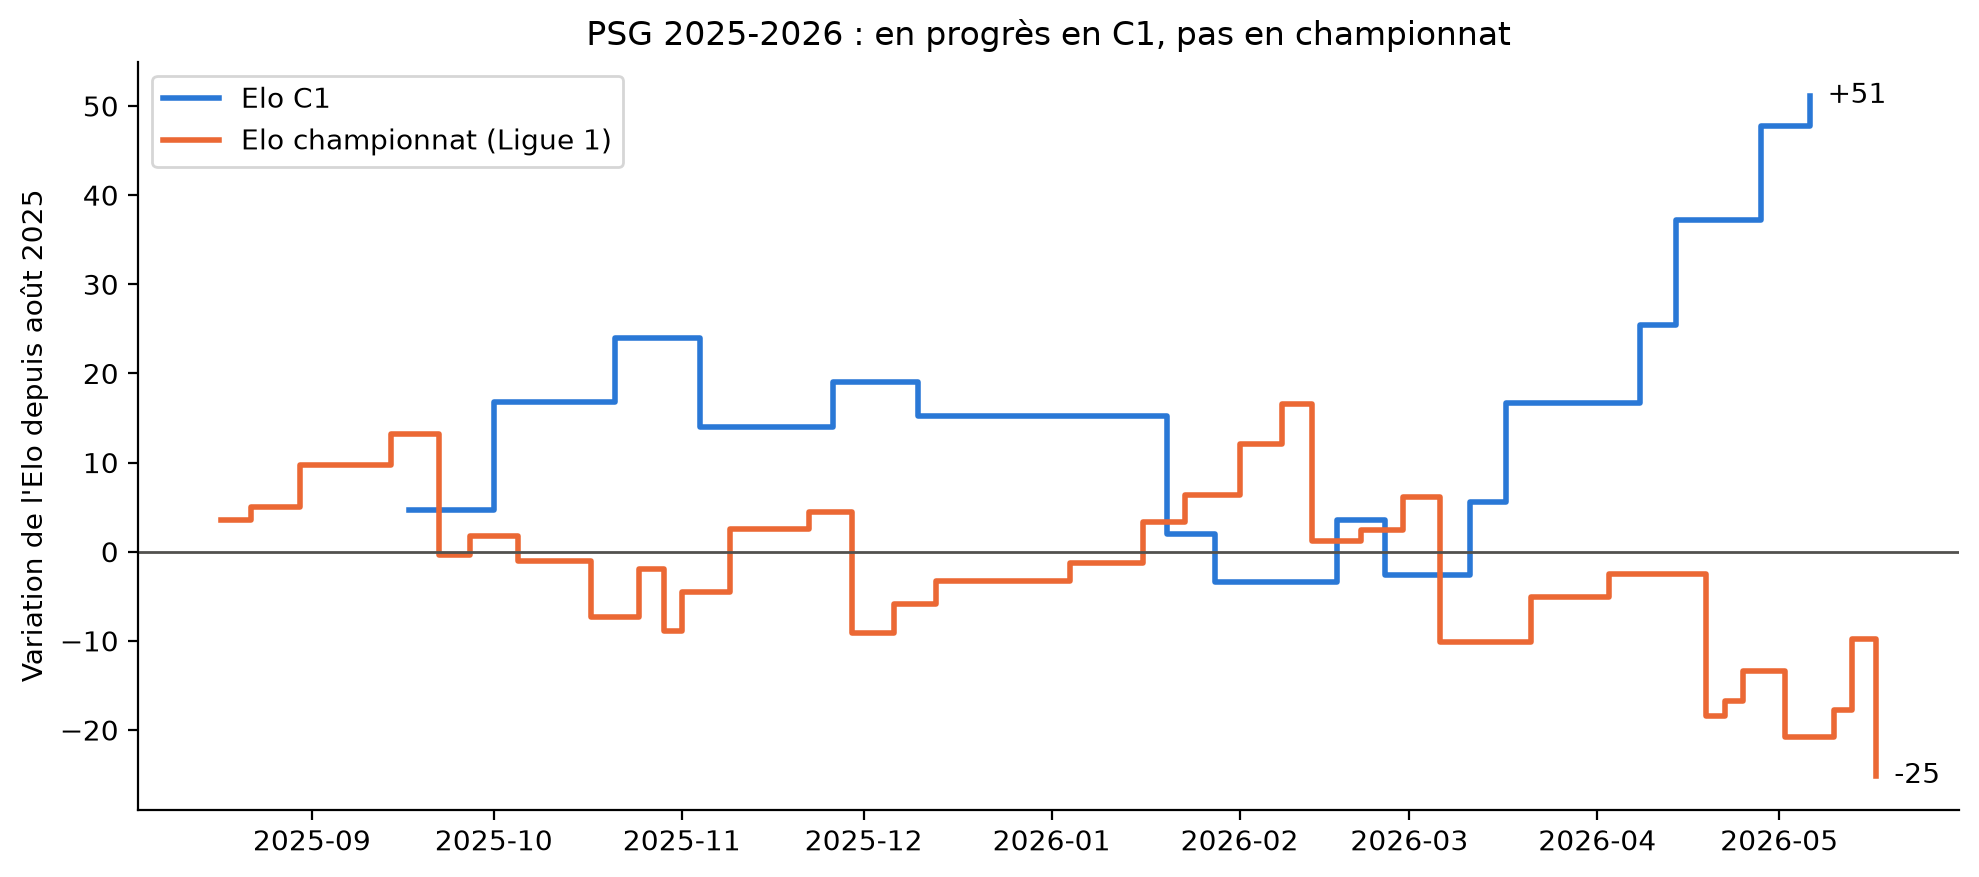

In [16]:
psg = matchs.loc[matchs['home_club_name'] == 'Paris Saint-Germain', 'home_club_id'].iloc[0]
debut = pd.Timestamp('2025-08-01')

fig, ax = plt.subplots(figsize=(10, 4.5))
for histo, nom, couleur in [(histo_c1, 'Elo C1', BLEU), (histo_champ, 'Elo championnat (Ligue 1)', ORANGE)]:
    serie = histo[(histo['club_id'] == psg) & (histo['date'] >= debut)].sort_values('date')
    depart = histo[(histo['club_id'] == psg) & (histo['date'] < debut)]['elo'].iloc[-1]   # Elo avant la saison
    variation = serie['elo'] - depart
    ax.step(serie['date'], variation, where='post', color=couleur, linewidth=2, label=nom)
    ax.text(serie['date'].iloc[-1], variation.iloc[-1], f"  {variation.iloc[-1]:+.0f}", va='center')
    print(f"{nom} : {depart:.0f} avant la saison → {serie['elo'].iloc[-1]:.0f} à la fin ({variation.iloc[-1]:+.0f})")

ax.axhline(0, color='#52514e', linewidth=1)
ax.set_ylabel("Variation de l'Elo depuis août 2025")
ax.set_title('PSG 2025-2026 : en progrès en C1, pas en championnat')
ax.legend(loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# 6. Les 36 participants de 2026-2027

**Question :** quel est le niveau de chaque participant **avant** la saison, et peut-on faire confiance à ce niveau ?

On prend le **dernier Elo** de chaque club (fin de la saison 2025-2026), dans les 3 versions. On ajoute le nombre de matchs disponibles, pour juger de la **fiabilité**. La liste des participants vient du site de l'UEFA.

**Résultat :**
- en Elo global, le haut du classement est cohérent avec l'Elo officiel (Bayern, Barcelone, Arsenal, Manchester City, Real Madrid, PSG) ;
- **6 participants n'ont jamais joué la C1** dans nos données : Como, Fenerbahçe, LASK, Real Betis, Sabah et Viking. Ils n'ont **pas d'Elo C1** ;
- certains clubs ont **très peu de matchs** : Sabah n'en a que 14, Viking une cinquantaine. Leur Elo est **peu fiable**.

**Ce que ça veut dire pour la suite :** pour la simulation, on utilisera l'**Elo global**, le seul qui existe pour les 36 clubs, et on signalera les clubs « peu fiables ».

In [17]:
participants = [   # noms tels qu'écrits dans games.csv (source de la liste : UEFA)
    'Athlitiki Enosi Konstantinoupoleos', 'Arsenal FC', 'Aston Villa', 'Atlético de Madrid', 'FC Barcelona',
    'Bayern Munich', 'Fotballklubben Bodø/Glimt', 'Borussia Dortmund', 'Club Brugge KV', 'Como 1907',
    'Fenerbahce', 'Feyenoord Rotterdam', 'Galatasaray', 'Inter Milan', 'LASK', 'RB Leipzig', 'RC Lens',
    'LOSC Lille', 'Liverpool FC', 'Manchester City', 'Manchester United', 'SSC Napoli', 'Paris Saint-Germain',
    'FC Porto', 'PSV Eindhoven', 'Real Betis Balompié', 'Real Madrid', 'Associazione Sportiva Roma', 'Sabah FK',
    'FC Shakhtar Donetsk', 'SK Slavia Prague', 'Slovan Bratislava', 'Sporting CP', 'VfB Stuttgart',
    'Viking Fotballklubb', 'Villarreal CF',
]
noms_ids = pd.concat([
    matchs[['home_club_name', 'home_club_id']].set_axis(['club', 'club_id'], axis=1),
    matchs[['away_club_name', 'away_club_id']].set_axis(['club', 'club_id'], axis=1),
]).drop_duplicates()
table = noms_ids[noms_ids['club'].isin(participants)].copy()
assert len(table) == 36, "un participant est introuvable ou en double"

# Dernier Elo connu de chaque club, dans chaque version
for histo, nom in [(histo_global, 'global'), (histo_c1, 'c1'), (histo_champ, 'champ')]:
    dernier = histo.sort_values('date').groupby('club_id')['elo'].last()
    table[f'elo_{nom}'] = table['club_id'].map(dernier).round(0)

# Fiabilité : combien de matchs avons-nous pour chaque club ?
tous_clubs = pd.concat([matchs['home_club_id'], matchs['away_club_id']])
clubs_c1 = pd.concat([matchs.loc[est_c1, 'home_club_id'], matchs.loc[est_c1, 'away_club_id']])
table['nb_matchs'] = table['club_id'].map(tous_clubs.value_counts())
table['nb_matchs_c1'] = table['club_id'].map(clubs_c1.value_counts()).fillna(0).astype(int)
table['fiabilite'] = np.where((table['nb_matchs'] < 100) | (table['nb_matchs_c1'] == 0), '⚠️ faible', 'bonne')

table = table.sort_values('elo_global', ascending=False).reset_index(drop=True)
table.index += 1
table

,club,club_id,elo_global,elo_c1,elo_champ,nb_matchs,nb_matchs_c1,fiabilite
1,Bayern Munich,27,2009.0,1767.0,1840.0,724,160,bonne
2,FC Barcelona,131,1967.0,1670.0,1806.0,800,142,bonne
3,Arsenal FC,11,1946.0,1683.0,1783.0,733,78,bonne
4,Manchester City,281,1914.0,1679.0,1763.0,764,139,bonne
5,Real Madrid,418,1913.0,1723.0,1772.0,809,170,bonne
6,Paris Saint-Germain,583,1888.0,1712.0,1789.0,678,148,bonne
7,Inter Milan,46,1871.0,1634.0,1813.0,703,72,bonne
8,PSV Eindhoven,383,1843.0,1503.0,1833.0,664,48,bonne
9,Sporting CP,336,1838.0,1523.0,1867.0,640,54,bonne
10,Borussia Dortmund,16,1829.0,1598.0,1712.0,693,124,bonne


# 7. Sauvegarde et conclusion

On sauvegarde deux tableaux dans `output/`, pour les autres notebooks du groupe :
- `elo_par_match.csv` : pour chaque match de C1 (`game_id`), les 3 Elo des deux clubs **avant** le match ;
- `elo_participants_2026.csv` : les 3 Elo et la fiabilité des 36 participants.

## Ce que nous avons appris
1. **Notre Elo global est fiable et complet** : il raconte la même histoire que l'Elo officiel (corrélation 0,78), avec un peu moins de précision (54,6 % contre 56,2 %), mais il couvre **100 %** des matchs, contre 80 %.
2. **L'Elo championnat ne sert pas à comparer des clubs de pays différents** (48 %, comme la règle « domicile gagne »). Pour la C1, il faut un Elo qui contient des matchs **entre pays**.
3. **L'Elo C1 prédit aussi bien que l'Elo global**, et il confirme le cas du PSG : en progrès en C1 en 2025-2026, pas en championnat.

## Limites
- Notre Elo part de 1 500 pour tous les clubs, avec des données qui commencent vers 2012 : les premières saisons sont moins fiables.
- Les clubs **russes**, exclus des coupes d'Europe depuis 2022, ne jouent plus que entre eux : leur Elo global n'est plus comparé aux autres pays, et peut être faussé.
- 6 participants n'ont pas d'Elo C1, et certains (Sabah, Viking) ont très peu de matchs.

## Pour le modèle
Utiliser l'**Elo global** comme variable principale (complet pour les 36 participants), tester l'**Elo C1** en complément, et **ne pas utiliser l'Elo championnat seul**.

In [18]:
os.makedirs('../output', exist_ok=True)

colonnes = ['game_id', 'date', 'season', 'home_club_id', 'away_club_id', 'home_club_name', 'away_club_name',
            'home_elo_global', 'away_elo_global', 'home_elo_c1', 'away_elo_c1', 'home_elo_champ', 'away_elo_champ']
c1[colonnes].to_csv('../output/elo_par_match.csv', index=False)
table.to_csv('../output/elo_participants_2026.csv', index=False)

print(f"output/elo_par_match.csv : {len(c1)} matchs de C1")
print(f"output/elo_participants_2026.csv : {len(table)} participants")

output/elo_par_match.csv : 1871 matchs de C1
output/elo_participants_2026.csv : 36 participants
